# 4 · Choosing the next experiments

The GP gives, for every possible recipe, a prediction μ and an uncertainty σ. The **expected improvement** (EI)
turns the two into one number: how much better than our current best can we hope to do here?

$$\text{EI} = (\mu - \text{best})\,\Phi(z) + \sigma\,\varphi(z), \qquad z = \frac{\mu - \text{best}}{\sigma}$$

* first term: the predicted gain, weighted by the chance of beating the best → **exploitation**
* second term: a bonus for uncertainty → **exploration**

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # use the local package without installing it
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nanobo as nb

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

## A classic interview question: recipe A or recipe B?

Our best score is 0.70.
**A**: predicted just above the best, and the model is very sure (μ = 0.71, σ = 0.01).
**B**: predicted below the best, but very uncertain (μ = 0.65, σ = 0.12).
Which one does EI prefer?

In [2]:
best = 0.70
cases = {"A  (mu 0.71, sigma 0.01)": (0.71, 0.01),
         "B  (mu 0.65, sigma 0.12)": (0.65, 0.12),
         "B' (mu 0.60, sigma 0.05)": (0.60, 0.05),
         "A2 (mu 0.73, sigma 0.01)": (0.73, 0.01)}
for name, (mu, sd) in cases.items():
    print(f"{name}:  EI = {nb.expected_improvement(mu, sd, best, xi=0.0):.4f}")

A  (mu 0.71, sigma 0.01):  EI = 0.0108
B  (mu 0.65, sigma 0.12):  EI = 0.0270
B' (mu 0.60, sigma 0.05):  EI = 0.0004
A2 (mu 0.73, sigma 0.01):  EI = 0.0300


**B wins** (about 2.5×): it has a real chance of beating 0.70 by a lot, while A can only gain about 0.01.
It depends on the numbers, though: B′ — uncertain but almost surely worse — is worth nothing, and if A were
predicted at 0.73 (A2) it would beat B. EI is a trade-off, not a rule.

## EI on a 1-D example

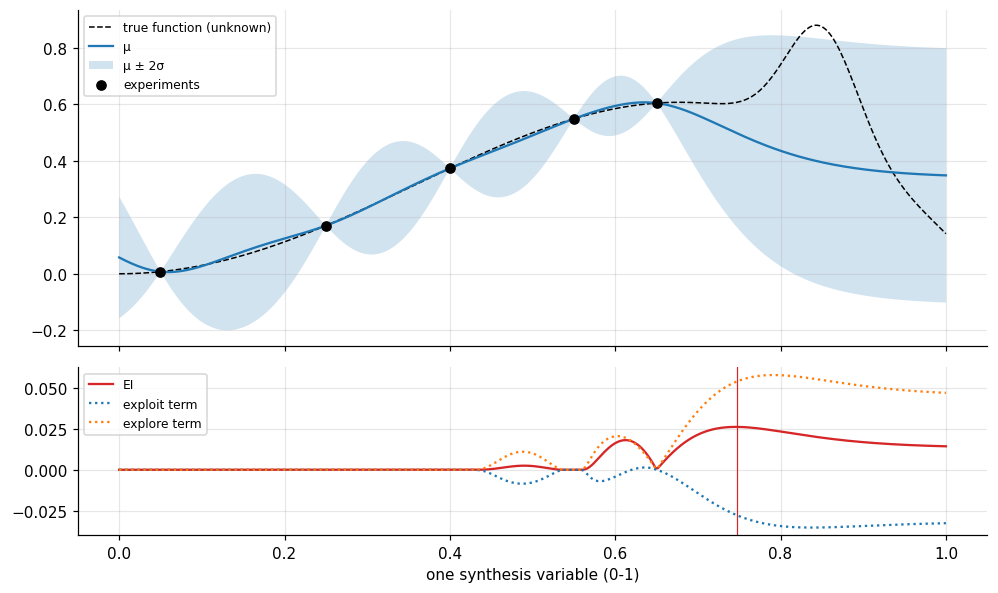

In [3]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C

f = lambda x: np.sin(3 * x) * x + 0.4 * np.exp(-((x - 0.85) / 0.06) ** 2)   # an arbitrary 1-D function
x_obs = np.array([0.05, 0.25, 0.4, 0.55, 0.65])
# length scale fixed at 0.12 for the illustration (with 5 points, a fitted one is unreliable)
gp1 = GaussianProcessRegressor(C(1.0, "fixed") * Matern(0.12, "fixed", nu=2.5), normalize_y=True, alpha=1e-6).fit(x_obs[:, None], f(x_obs))
xs = np.linspace(0, 1, 400)
mu, sd = gp1.predict(xs[:, None], return_std=True)
ei = nb.expected_improvement(mu, sd, f(x_obs).max(), xi=0.0)
imp = mu - f(x_obs).max(); z = imp / np.maximum(sd, 1e-12)
from scipy.stats import norm

fig, ax = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(xs, f(xs), "k--", lw=1, label="true function (unknown)")
ax[0].plot(xs, mu, label="μ"); ax[0].fill_between(xs, mu - 2 * sd, mu + 2 * sd, alpha=0.2, label="μ ± 2σ")
ax[0].scatter(x_obs, f(x_obs), c="k", zorder=5, label="experiments"); ax[0].legend(fontsize=8)
ax[1].plot(xs, ei, c="C3", label="EI"); ax[1].plot(xs, imp * norm.cdf(z), ":", label="exploit term")
ax[1].plot(xs, sd * norm.pdf(z), ":", label="explore term"); ax[1].axvline(xs[np.argmax(ei)], c="C3", lw=0.8)
ax[1].legend(fontsize=8); ax[1].set_xlabel("one synthesis variable (0-1)")
plt.tight_layout(); plt.show()

## Choosing a batch: why not simply the 6 highest EI values?

Real syntheses are run in batches. The 6 highest EI values sit next to each other — six almost identical
experiments. The **kriging believer** picks one recipe, *pretends* the GP prediction there is the result, refits
(keeping the learned kernel frozen), and picks again: the uncertainty around the first pick collapses, so the
second pick goes elsewhere. Here is the loop written out on the 1-D example.

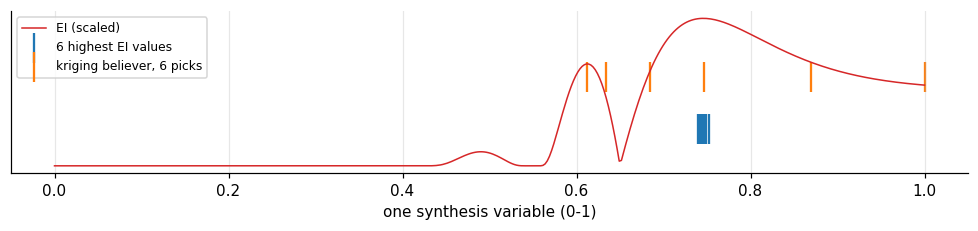

naive top-6 : [0.739 0.742 0.744 0.747 0.749 0.752]
believer    : [0.612 0.634 0.684 0.747 0.87  1.   ]


In [4]:
from sklearn.base import clone

top6 = xs[np.argsort(ei)[-6:]]                       # naive: the 6 best EI values

x_aug, y_aug, kb = list(x_obs), list(f(x_obs)), []
best = f(x_obs).max()
for _ in range(6):
    g = GaussianProcessRegressor(gp1.kernel_, optimizer=None, normalize_y=True, alpha=1e-6)
    g.fit(np.array(x_aug)[:, None], np.array(y_aug))
    m, s = g.predict(xs[:, None], return_std=True)
    j = int(np.argmax(nb.expected_improvement(m, s, best, xi=0.0)))
    kb.append(xs[j]); x_aug.append(xs[j]); y_aug.append(m[j])   # believe the prediction
    best = max(best, m[j])                                       # ...which may become the new best

fig, ax = plt.subplots(figsize=(9, 2.2))
ax.plot(xs, ei / ei.max(), c="C3", lw=1, label="EI (scaled)")
ax.scatter(top6, np.full(6, 0.25), marker="|", s=400, label="6 highest EI values")
ax.scatter(kb, np.full(6, 0.6), marker="|", s=400, label="kriging believer, 6 picks")
ax.set_yticks([]); ax.set_xlabel("one synthesis variable (0-1)"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
print("naive top-6 :", np.round(np.sort(top6), 3))
print("believer    :", np.round(np.sort(kb), 3))

In three dimensions, `nanobo.kriging_believer` does the same with 5 000 candidate recipes (and also refuses
near-duplicates):

In [5]:
lab = nb.VirtualLab(seed=1)
X = nb.latin_hypercube(12, seed=3); y = nb.desirability_score(*lab.run(X)); U = nb.to_unit(X)
gp = nb.make_gp().fit(U, y)
kb6, details = nb.kriging_believer(gp, U, y, 6, n_candidates=5000, seed=7, return_details=True)
picks = pd.DataFrame(nb.from_unit(kb6), columns=nb.SHORT)
picks["predicted score"] = [d["mu"] for d in details]
picks["sigma"] = [d["sigma"] for d in details]
picks.index = [f"pick {i+1}" for i in range(6)]
picks.round(3)

,conc_M,ratio_OA_Fe,temp_C,predicted score,sigma
pick 1,0.291,4.991,300.319,0.930,0.084
pick 2,0.298,4.889,318.835,0.898,0.079
pick 3,0.298,4.036,287.497,0.775,0.156
pick 4,0.300,4.935,284.356,0.874,0.066
pick 5,0.051,4.733,316.119,0.143,0.410
pick 6,0.299,1.001,292.319,0.252,0.339


## "Best so far": measured or predicted?

EI needs a *best* value to beat. The highest **measured** score is often a lucky, noisy measurement, which sets the
bar too high. `nanobo` uses the highest **predicted** score among recipes already made (`incumbent(kind="posterior")`),
a simple guard against chasing a lucky tube. (Libraries such as BoTorch handle this more rigorously with *noisy EI*.)

In [6]:
# 16 hypercube recipes + 4 repeats of one good recipe, so that the GP can learn the noise
lab = nb.VirtualLab(seed=4)
X = np.vstack([nb.latin_hypercube(16, seed=14), np.repeat(nb.from_unit([[0.7, 0.8, 0.75]]), 4, axis=0)])
y = nb.desirability_score(*lab.run(X)); U = nb.to_unit(X)
gp = nb.make_gp().fit(U, y)
print("the 4 repeats of the same recipe scored:", np.round(y[-4:], 2))
print(f"best measured: {nb.incumbent(gp, U, y, 'observed'):.3f}   "
      f"best predicted at a made recipe: {nb.incumbent(gp, U, y):.3f}")

the 4 repeats of the same recipe scored: [0.58 1.   0.88 0.79]
best measured: 0.999   best predicted at a made recipe: 0.760


## Take-aways

* EI balances **exploiting** good predictions and **exploring** uncertain regions.
* A batch must be chosen **jointly**; the kriging believer is the simplest way.
* With noisy data, compare against a **predicted** best, not a lucky measurement.